# Predicting Commuting Time in South Africa

## 1. Data Loading and Initial Exploration

In [17]:
# Importing libraries for data manipulation, ZIP file handling, and file paths
import pandas as pd
import zipfile
from pathlib import Path

In [18]:
# Defining the path to the compressed survey dataset
dataset_path = Path("../data/nhts-2020-v1.zip")

# Opening the ZIP file and loading the Stata person-level dataset
with zipfile.ZipFile(dataset_path) as z:
    with z.open("nhts-2020-v1/nhts-2020-v1-stata/nhts-2020-person.dta") as f:
        df = pd.read_stata(f, convert_categoricals=False)

# Checking the number of rows and columns in the dataset
print(df.shape)

(145385, 274)


In [19]:
#Selecting eight independent variables

features= [
    "Age",
    "Sex",
    "Q43SectOfWork",
    "Q48bDMunic",
    "Q49Days",
    "Q420OffiTime",
    "Q413EmployCash",
    "Mainmode_work"
]

#Defining what we want to predict

target = "Tot_time_travel_work"

#Selecting the features and target from the original dataset

commute_df = df[features + [target]].copy()

#Checking the dimensions
print("Dataset shape:", commute_df.shape)

#Displaying the first five observations

commute_df.head()

Dataset shape: (145385, 9)


,Age,Sex,Q43SectOfWork,Q48bDMunic,Q49Days,Q420OffiTime,Q413EmployCash,Mainmode_work,Tot_time_travel_work
0,66,2,8,99,9,9999,9,8,999
1,39,1,1,12,5,0730,2,6,20
2,7,1,9,99,9,9999,9,8,999
3,25,1,1,12,5,0700,2,6,20
4,23,2,8,99,9,9999,9,8,999


In [20]:
# Examining the distribution of commuting times

print(commute_df["Tot_time_travel_work"].describe())

#Count unspecified commuting times

print(
    "Unspecified records:",
    (commute_df["Tot_time_travel_work"] == 999). sum()
)

count    145385.000000
mean        821.913340
std         371.267026
min           1.000000
25%         999.000000
50%         999.000000
75%         999.000000
max         999.000000
Name: Tot_time_travel_work, dtype: float64
Unspecified records: 118404


In [21]:
# Removing invalid target values

commute_df = commute_df[ commute_df["Tot_time_travel_work"].between(1, 365)].copy()
print("Remaining records:", len(commute_df))
print(commute_df["Tot_time_travel_work"].describe())

Remaining records: 26981
count    26981.000000
mean        44.782439
std         34.332372
min          1.000000
25%         20.000000
50%         35.000000
75%         60.000000
max        365.000000
Name: Tot_time_travel_work, dtype: float64


In [22]:
# Checking missing values in each of the selected column

print(commute_df.isnull().sum())

#Examining the number of unique values in each feature

print(commute_df[features].nunique())

Age                     0
Sex                     0
Q43SectOfWork           0
Q48bDMunic              0
Q49Days                 0
Q420OffiTime            0
Q413EmployCash          0
Mainmode_work           0
Tot_time_travel_work    0
dtype: int64
Age                72
Sex                 2
Q43SectOfWork       5
Q48bDMunic         53
Q49Days             8
Q420OffiTime      135
Q413EmployCash      2
Mainmode_work       8
dtype: int64


In [23]:
# Identifying records with valid values across the seven selected features
valid = (
    commute_df["Age"].between(15,120)
    & commute_df["Sex"].isin([1,2])
    & commute_df["Q43SectOfWork"].isin ([1,2,3])
    & commute_df["Q48bDMunic"].between (11,70)
    & commute_df["Q49Days"].between (1,7)
    & commute_df["Q413EmployCash"].isin([1,2])
    & commute_df["Mainmode_work"].between(1,7)

)
print("Records passing seven feature checks:", valid.sum())

Records passing seven feature checks: 24492


In [24]:
# Converting work start "times to strings
time= commute_df["Q420OffiTime"].astype(str).str.zfill(4)

# Checking whether hours and minutes are valid

valid_time= (
    time.str.fullmatch(r"\d{4}")
    & (pd.to_numeric(time.str[:2], errors="coerce") < 24)
    & (pd.to_numeric(time.str[:2], errors="coerce") < 60)
)

# Combining all the eight feature checks

valid= valid & valid_time

print("Records passing all eight checks:", valid.sum())

Records passing all eight checks: 24492


In [25]:
# Keeping only records that passed all eight checks
commute_df = commute_df[valid].copy()

# Resetting the row numbering
commute_df = commute_df.reset_index(drop=True)

# Checking the cleaned dataset
print("Final dataset shape:", commute_df.shape)

commute_df.head()

Final dataset shape: (24492, 9)


,Age,Sex,Q43SectOfWork,Q48bDMunic,Q49Days,Q420OffiTime,Q413EmployCash,Mainmode_work,Tot_time_travel_work
0,39,1,1,12,5,0730,2,6,20
1,25,1,1,12,5,0700,2,6,20
2,62,2,1,12,5,0730,2,6,10
3,37,1,1,12,5,0700,2,4,25
4,28,1,1,12,5,0700,2,4,25


In [26]:
# Converting official work start time into minutes after midnight
work_time = commute_df["Q420OffiTime"].astype(str).str.zfill(4)

hours = work_time.str[:2].astype(int)
minutes = work_time.str[2:].astype(int)

commute_df["WorkStartMinutes"] = hours * 60 + minutes

# Comparing the original and transformed values
commute_df[["Q420OffiTime", "WorkStartMinutes"]].head()

,Q420OffiTime,WorkStartMinutes
0,0730,450
1,0700,420
2,0730,450
3,0700,420
4,0700,420


In [27]:
# Identifying numerical features
numerical_features = [
    "Age",
    "Q49Days",
    "WorkStartMinutes"
]

# Identifying categorical features
categorical_features = [
    "Sex",
    "Q43SectOfWork",
    "Q48bDMunic",
    "Q413EmployCash",
    "Mainmode_work"
]

# Combining all eight model features
model_features = numerical_features + categorical_features

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total model features:", len(model_features))

Numerical features: 3
Categorical features: 5
Total model features: 8


In [28]:
#Importing libraries for visualisations
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


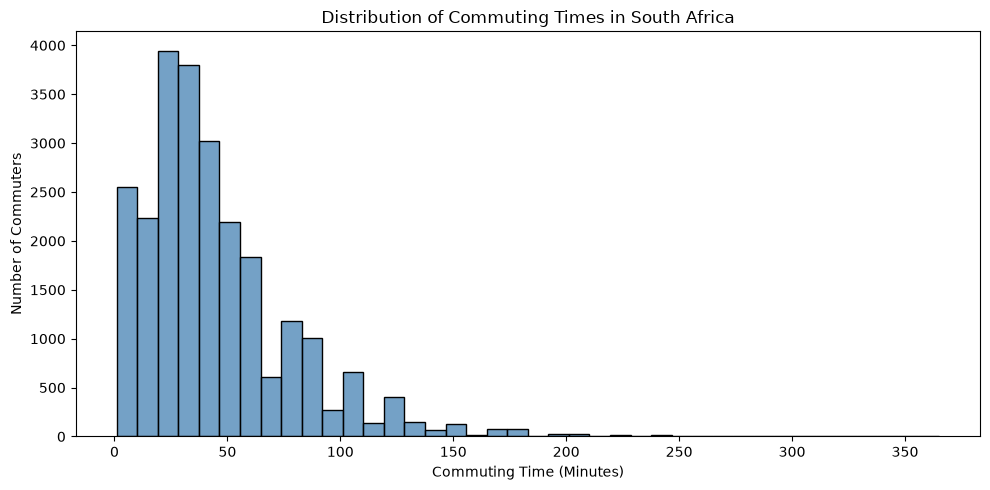

In [29]:
# Visualizing the distribution of commuting times
plt.figure(figsize=(10, 5))

sns.histplot(
    data=commute_df,
    x="Tot_time_travel_work",
    bins=40,
    color="steelblue"
)

plt.title("Distribution of Commuting Times in South Africa")
plt.xlabel("Commuting Time (Minutes)")
plt.ylabel("Number of Commuters")

plt.tight_layout()
plt.show()

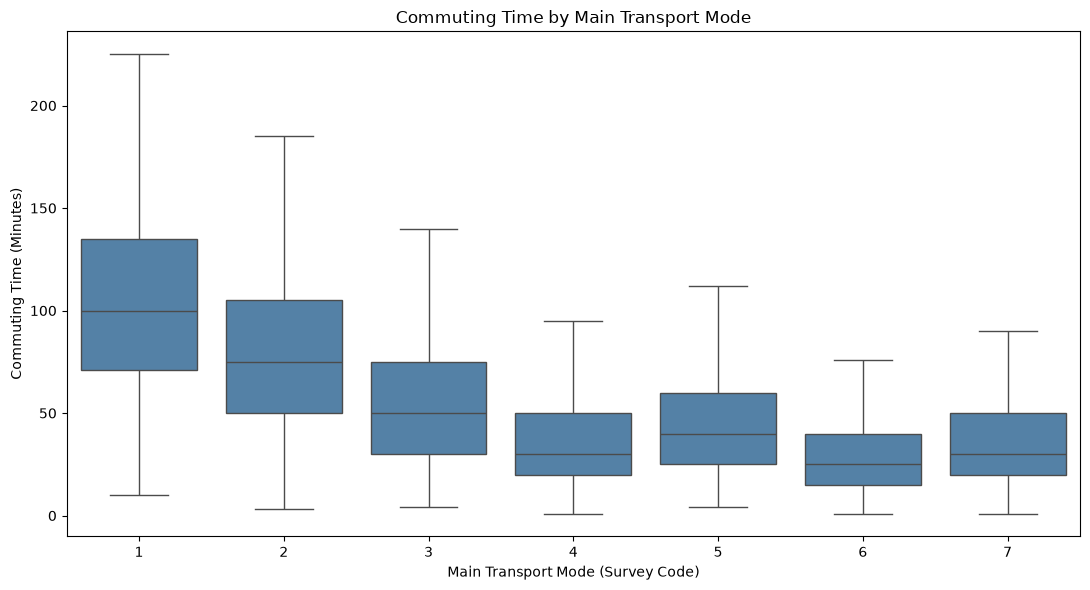

In [30]:
# Comparing commuting times across different transport modes
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=commute_df,
    x="Mainmode_work",
    y="Tot_time_travel_work",
    color="steelblue",
    showfliers=False
)

plt.title("Commuting Time by Main Transport Mode")
plt.xlabel("Main Transport Mode (Survey Code)")
plt.ylabel("Commuting Time (Minutes)")

plt.tight_layout()
plt.show()

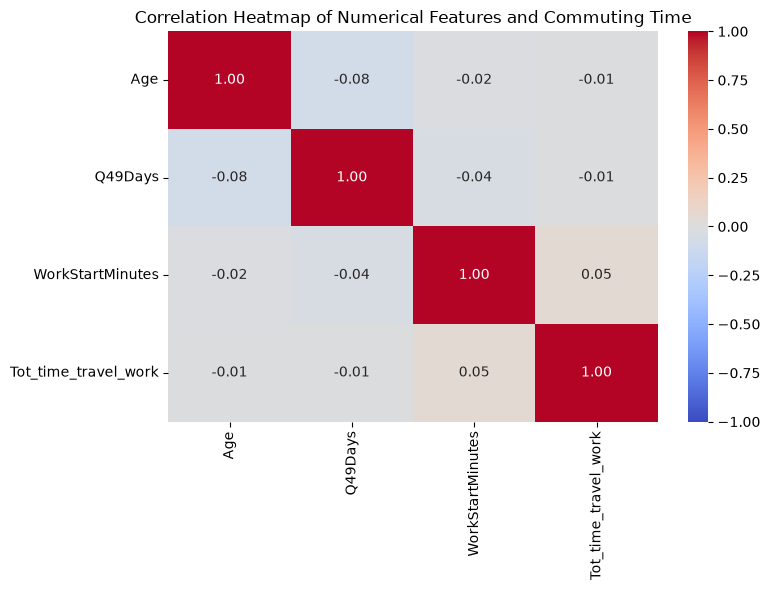

In [31]:
# Selecting numerical features and the target for correlation analysis
correlation_columns = numerical_features + [target]

# Calculating Pearson correlation coefficients
correlation_matrix = commute_df[correlation_columns].corr()

# Visualizing the correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features and Commuting Time")
plt.tight_layout()
plt.show()

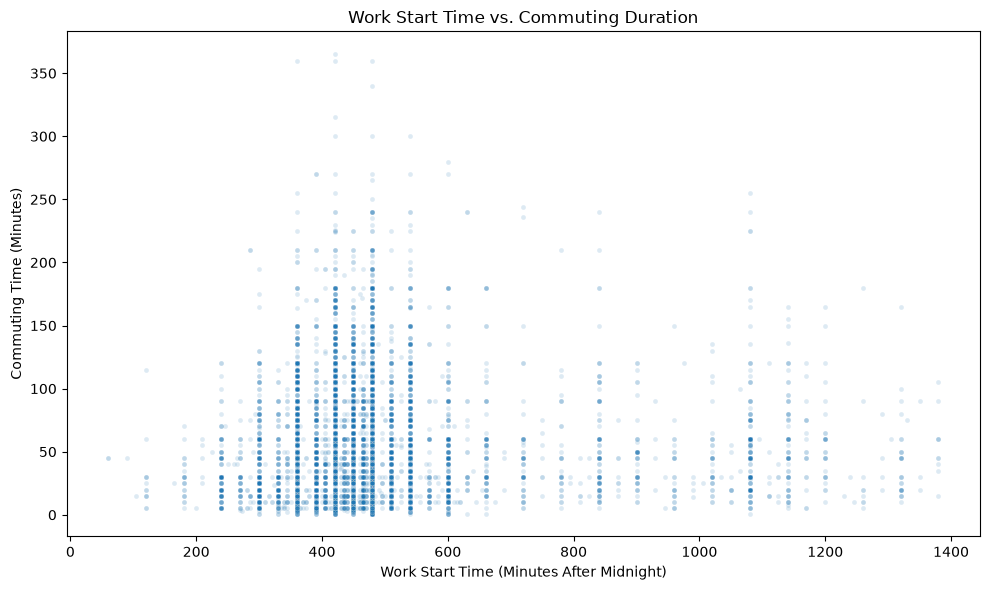

In [32]:
# Exploring the relationship between work start time and commuting duration
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=commute_df,
    x="WorkStartMinutes",
    y="Tot_time_travel_work",
    alpha=0.15,
    s=12
)

plt.title("Work Start Time vs. Commuting Duration")
plt.xlabel("Work Start Time (Minutes After Midnight)")
plt.ylabel("Commuting Time (Minutes)")

plt.tight_layout()
plt.show()

In [33]:
# Comparing commuting times across categorical features
for feature in categorical_features:
    summary = commute_df.groupby(feature)[target].agg(
        Count="count",
        Median="median",
        Mean="mean"
    )

    print(f"\n{feature}")
    print(summary.round(2))


Sex
     Count  Median   Mean
Sex                      
1    13122    39.5  45.76
2    11370    35.0  44.03

Q43SectOfWork
               Count  Median   Mean
Q43SectOfWork                      
1              15676    40.0  45.91
2               5738    30.0  42.53
3               3078    30.0  44.66

Q48bDMunic
            Count  Median   Mean
Q48bDMunic                      
11            696    50.0  60.47
12            270    25.0  32.53
13            937    25.0  29.81
14            359    20.0  27.19
15            702    30.0  33.44
16            348    15.0  21.33
18            463    25.0  31.25
19            293    30.0  32.80
20            279    30.0  34.09
21            185    20.0  35.08
22            247    35.0  43.73
23            300    30.0  36.18
24            425    40.0  43.41
25            424    35.0  42.48
27            278    30.0  40.55
28            165    20.0  25.27
29            127    20.0  23.14
30            329    25.0  33.46
31            162    30.

In [34]:
# Checking whether municipality codes fall within the expected valid range
print("Minimum municipality code:", commute_df["Q48bDMunic"].min())
print("Maximum municipality code:", commute_df["Q48bDMunic"].max())

# Counting records with municipality codes outside the accepted range
print(
    "Invalid municipality records:",
    (~commute_df["Q48bDMunic"].between(11, 70)).sum()
)

Minimum municipality code: 11
Maximum municipality code: 70
Invalid municipality records: 0


In [35]:
from sklearn.model_selection import train_test_split

# Separating independent variables (X) and the target (y)
X = commute_df[model_features]
y = commute_df[target]

# Splitting the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Checking the size of each dataset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (19593, 8)
Testing features: (4899, 8)
Training targets: (19593,)
Testing targets: (4899,)


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Defining transformations for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Age', 'Q49Days', 'WorkStartMinutes']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Sex', 'Q43SectOfWork', 'Q48bDMunic',
                                  'Q413EmployCash', 'Mainmode_work'])])


In [39]:
# Importing the required libraries
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

In [40]:

# Creating a pipeline that combines preprocessing and Linear Regression
linear_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

# Training the model using the training dataset
linear_pipeline.fit(X_train, y_train)

# Predicting commuting times for training and testing datasets
train_predictions = linear_pipeline.predict(X_train)
test_predictions = linear_pipeline.predict(X_test)

# Calculating Mean Squared Error for both datasets
train_mse = mean_squared_error(y_train, train_predictions)
test_mse = mean_squared_error(y_test, test_predictions)

# Displaying the model's performance
print("Linear Regression Results")
print(f"Training MSE: {train_mse:.2f}")
print(f"Testing MSE: {test_mse:.2f}")

Linear Regression Results
Training MSE: 879.70
Testing MSE: 912.32


In [41]:
# Creating a pipeline with preprocessing and SGD Regression
sgd_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SGDRegressor(
        loss="squared_error",
        learning_rate="invscaling",
        eta0=0.01,
        alpha=0.0001,
        max_iter=2000,
        tol=1e-3,
        random_state=42
    ))
])

# Training the SGD model
sgd_pipeline.fit(X_train, y_train)

# Predicting commuting times on training and testing datasets
sgd_train_predictions = sgd_pipeline.predict(X_train)
sgd_test_predictions = sgd_pipeline.predict(X_test)

# Calculating Mean Squared Error
sgd_train_mse = mean_squared_error(y_train, sgd_train_predictions)
sgd_test_mse = mean_squared_error(y_test, sgd_test_predictions)

# Displaying SGD performance
print("SGD Regression Results")
print(f"Training MSE: {sgd_train_mse:.2f}")
print(f"Testing MSE: {sgd_test_mse:.2f}")

SGD Regression Results
Training MSE: 881.08
Testing MSE: 913.21


In [42]:

# Creating a pipeline with preprocessing and Decision Tree Regression
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=10,
        random_state=42
    ))
])

# Training the Decision Tree model
tree_pipeline.fit(X_train, y_train)

# Predicting commuting times for training and testing datasets
tree_train_predictions = tree_pipeline.predict(X_train)
tree_test_predictions = tree_pipeline.predict(X_test)

# Calculating Mean Squared Error for both datasets
tree_train_mse = mean_squared_error(y_train, tree_train_predictions)
tree_test_mse = mean_squared_error(y_test, tree_test_predictions)

# Displaying the model's performance
print("Decision Tree Regression Results")
print(f"Training MSE: {tree_train_mse:.2f}")
print(f"Testing MSE: {tree_test_mse:.2f}")

Decision Tree Regression Results
Training MSE: 837.79
Testing MSE: 954.27


In [43]:
# Creating a pipeline with preprocessing and Random Forest Regression
forest_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Training the Random Forest model
forest_pipeline.fit(X_train, y_train)

# Predicting commuting times for training and testing datasets
forest_train_predictions = forest_pipeline.predict(X_train)
forest_test_predictions = forest_pipeline.predict(X_test)

# Calculating Mean Squared Error for both datasets
forest_train_mse = mean_squared_error(y_train, forest_train_predictions)
forest_test_mse = mean_squared_error(y_test, forest_test_predictions)

# Displaying the model's performance
print("Random Forest Regression Results")
print(f"Training MSE: {forest_train_mse:.2f}")
print(f"Testing MSE: {forest_test_mse:.2f}")

Random Forest Regression Results
Training MSE: 823.73
Testing MSE: 919.33


In [44]:
# Creating a comparison table for all four regression models
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "SGD Regressor",
        "Decision Tree",
        "Random Forest"
    ],
    "Training MSE": [
        train_mse,
        sgd_train_mse,
        tree_train_mse,
        forest_train_mse
    ],
    "Testing MSE": [
        test_mse,
        sgd_test_mse,
        tree_test_mse,
        forest_test_mse
    ]
})

# Sorting models by testing MSE (lower is better)
model_results = model_results.sort_values(
    by="Testing MSE"
).reset_index(drop=True)

# Displaying the comparison table
display(model_results.round(2))

,Model,Training MSE,Testing MSE
0,Linear Regression,879.70,912.32
1,SGD Regressor,881.08,913.21
2,Random Forest,823.73,919.33
3,Decision Tree,837.79,954.27


In [45]:
# Importing the tools for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Creating an SGD pipeline for hyperparameter tuning
sgd_tuning_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SGDRegressor(
        random_state=42,
        max_iter=2000,
        tol=1e-3
    ))
])

# Defining the hyperparameter combinations to investigate
sgd_param_grid = {
    "model__loss": ["squared_error", "huber"],
    "model__eta0": [0.001, 0.01, 0.1],
    "model__alpha": [0.0001, 0.001],
    "model__learning_rate": ["invscaling"]
}

# Searching for the best configuration using 3-fold cross-validation
sgd_search = GridSearchCV(
    estimator=sgd_tuning_pipeline,
    param_grid=sgd_param_grid,
    scoring="neg_mean_squared_error",
    cv=3,
    n_jobs=-1
)

# Fitting only on the training dataset to avoid test-data leakage
sgd_search.fit(X_train, y_train)

# Displaying the best hyperparameters and cross-validation MSE
print("Best SGD Parameters:")
print(sgd_search.best_params_)

print(f"\nBest Cross-Validation MSE: {-sgd_search.best_score_:.2f}")

Best SGD Parameters:
{'model__alpha': 0.0001, 'model__eta0': 0.001, 'model__learning_rate': 'invscaling', 'model__loss': 'squared_error'}

Best Cross-Validation MSE: 887.70


In [46]:
# Retrieving the best SGD pipeline from GridSearchCV
best_sgd_pipeline = sgd_search.best_estimator_

# Predicting commuting times using the tuned model
best_sgd_train_pred = best_sgd_pipeline.predict(X_train)
best_sgd_test_pred = best_sgd_pipeline.predict(X_test)

# Calculating training and testing MSE
best_sgd_train_mse = mean_squared_error(y_train, best_sgd_train_pred)
best_sgd_test_mse = mean_squared_error(y_test, best_sgd_test_pred)

# Displaying the selected parameters and model performance
print("Best SGD Parameters:")
for parameter, value in sgd_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nTuned SGD Results")
print(f"Training MSE: {best_sgd_train_mse:.2f}")
print(f"Testing MSE: {best_sgd_test_mse:.2f}")

Best SGD Parameters:
model__alpha: 0.0001
model__eta0: 0.001
model__learning_rate: invscaling
model__loss: squared_error

Tuned SGD Results
Training MSE: 880.10
Testing MSE: 913.09


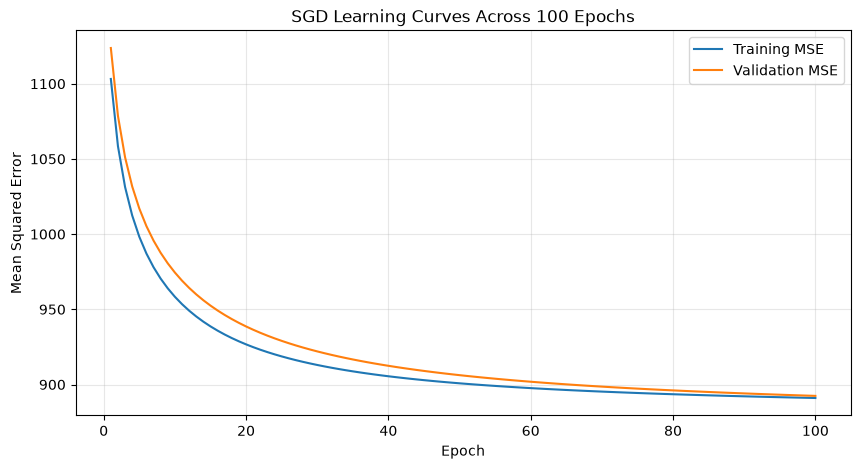

Final Training MSE: 891.03
Final Validation MSE: 892.43


In [47]:
# Importing the required libraries
from sklearn.base import clone
from sklearn.model_selection import train_test_split

# Splitting the training data into training and validation subsets
X_sgd_train, X_sgd_val, y_sgd_train, y_sgd_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42
)

# Fitting preprocessing only on the SGD training subset
sgd_preprocessor = clone(preprocessor)

X_sgd_train_scaled = sgd_preprocessor.fit_transform(X_sgd_train)
X_sgd_val_scaled = sgd_preprocessor.transform(X_sgd_val)

# Creating SGD using the best hyperparameters from GridSearchCV
sgd_epoch_model = SGDRegressor(
    loss="squared_error",
    alpha=0.0001,
    learning_rate="invscaling",
    eta0=0.001,
    random_state=42
)

# Creating lists to store MSE after every epoch
train_mse_history = []
val_mse_history = []

# Training SGD incrementally for 100 epochs
for epoch in range(100):

    # Performing one pass over the training data
    sgd_epoch_model.partial_fit(X_sgd_train_scaled, y_sgd_train)

    # Predicting on training and validation data
    epoch_train_pred = sgd_epoch_model.predict(X_sgd_train_scaled)
    epoch_val_pred = sgd_epoch_model.predict(X_sgd_val_scaled)

    # Recording MSE for this epoch
    train_mse_history.append(
        mean_squared_error(y_sgd_train, epoch_train_pred)
    )

    val_mse_history.append(
        mean_squared_error(y_sgd_val, epoch_val_pred)
    )

# Plotting training and validation MSE across epochs
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 101),
    train_mse_history,
    label="Training MSE"
)

plt.plot(
    range(1, 101),
    val_mse_history,
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("SGD Learning Curves Across 100 Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Displaying the final MSE values
print(f"Final Training MSE: {train_mse_history[-1]:.2f}")
print(f"Final Validation MSE: {val_mse_history[-1]:.2f}")

In [49]:
# Importing Huber loss evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Defining the loss functions to compare
loss_functions = ["squared_error", "huber"]

# Storing comparison results
loss_results = []

for loss_name in loss_functions:

    # Creating an SGD model with the selected loss function
    model = SGDRegressor(
        loss=loss_name,
        alpha=0.0001,
        learning_rate="invscaling",
        eta0=0.001,
        max_iter=2000,
        tol=1e-3,
        random_state=42
    )

    # Training using the same preprocessed training subset
    model.fit(X_sgd_train_scaled, y_sgd_train)

    # Predicting on the same validation subset
    predictions = model.predict(X_sgd_val_scaled)

    # Recording evaluation metrics
    loss_results.append({
        "Training Loss": loss_name,
        "Validation MSE": mean_squared_error(y_sgd_val, predictions),
        "Validation MAE": mean_absolute_error(y_sgd_val, predictions)
    })

# Displaying the comparison table
loss_comparison = pd.DataFrame(loss_results)

display(loss_comparison.round(2))

,Training Loss,Validation MSE,Validation MAE
0,squared_error,878.57,21.46
1,huber,1641.63,26.86


In [50]:
# Importing NumPy for numerical calculations
import numpy as np

# Defining Huber loss with a 10-minute threshold
def calculate_huber_loss(y_true, y_pred, delta=10):
    errors = np.asarray(y_true) - np.asarray(y_pred)
    absolute_errors = np.abs(errors)

    # Squared penalty for small errors, linear penalty for large errors
    losses = np.where(
        absolute_errors <= delta,
        0.5 * errors**2,
        delta * (absolute_errors - 0.5 * delta)
    )

    return np.mean(losses)


# Comparing both SGD training objectives using the same metrics
huber_results = []

for loss_name in ["squared_error", "huber"]:

    # Creating and training the SGD model
    model = SGDRegressor(
        loss=loss_name,
        alpha=0.0001,
        learning_rate="invscaling",
        eta0=0.001,
        max_iter=2000,
        tol=1e-3,
        random_state=42
    )

    model.fit(X_sgd_train_scaled, y_sgd_train)

    # Predicting on the validation dataset
    predictions = model.predict(X_sgd_val_scaled)

    # Recording both evaluation metrics
    huber_results.append({
        "Training Loss": loss_name,
        "Validation MSE": mean_squared_error(y_sgd_val, predictions),
        "Validation Huber Loss": calculate_huber_loss(
            y_sgd_val, predictions, delta=10
        )
    })

# Displaying the comparison
huber_comparison = pd.DataFrame(huber_results)
display(huber_comparison.round(2))

,Training Loss,Validation MSE,Validation Huber Loss
0,squared_error,878.57,169.51
1,huber,1641.63,224.79


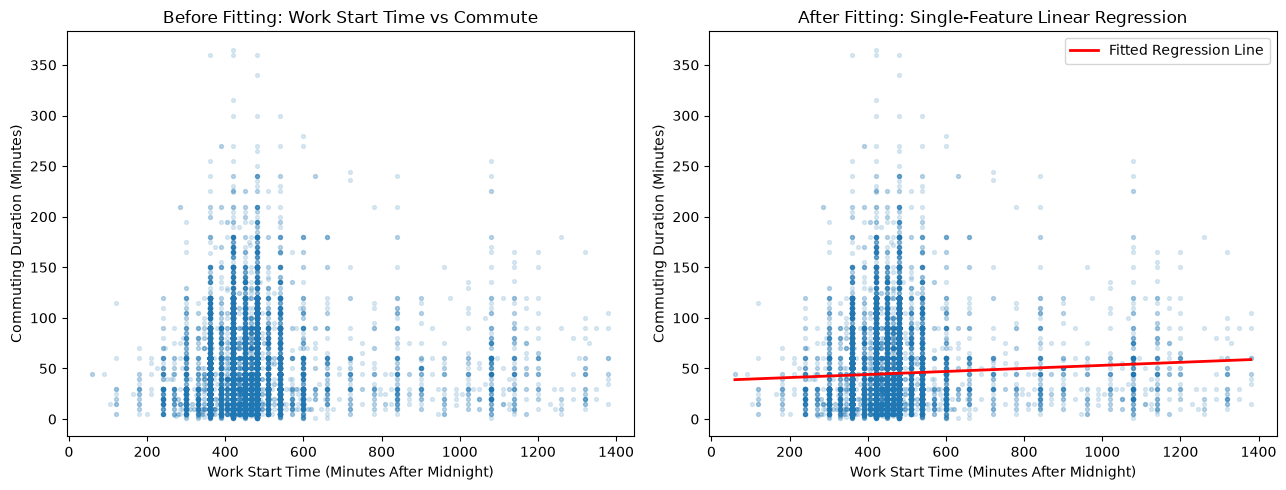

Coefficient: 0.0150
Intercept: 38.06


In [51]:
# Selecting the numerical feature most correlated with commuting time
feature = "WorkStartMinutes"

# Preparing the feature and target
X_single = commute_df[[feature]]
y_single = commute_df[target]

# Training a single-feature Linear Regression model
single_model = LinearRegression()
single_model.fit(X_single, y_single)

# Generating predictions for the regression line
x_line = np.linspace(X_single[feature].min(), X_single[feature].max(), 200)
y_line = single_model.predict(
    pd.DataFrame({feature: x_line})
)

# Creating before-and-after visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Before fitting: original data
axes[0].scatter(
    X_single[feature], y_single,
    alpha=0.15, s=8
)
axes[0].set_title("Before Fitting: Work Start Time vs Commute")
axes[0].set_xlabel("Work Start Time (Minutes After Midnight)")
axes[0].set_ylabel("Commuting Duration (Minutes)")

# After fitting: original data with fitted regression line
axes[1].scatter(
    X_single[feature], y_single,
    alpha=0.15, s=8
)
axes[1].plot(
    x_line, y_line,
    color="red", linewidth=2,
    label="Fitted Regression Line"
)
axes[1].set_title("After Fitting: Single-Feature Linear Regression")
axes[1].set_xlabel("Work Start Time (Minutes After Midnight)")
axes[1].set_ylabel("Commuting Duration (Minutes)")
axes[1].legend()

plt.tight_layout()
plt.show()

# Displaying the learned relationship
print(f"Coefficient: {single_model.coef_[0]:.4f}")
print(f"Intercept: {single_model.intercept_:.2f}")

In [52]:
# Importing DummyRegressor for baseline comparison
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

# Creating a baseline model that always predicts the training mean
baseline_model = DummyRegressor(strategy="mean")

# Training the baseline model
baseline_model.fit(X_train, y_train)

# Predicting commuting times using the baseline
baseline_train_pred = baseline_model.predict(X_train)
baseline_test_pred = baseline_model.predict(X_test)

# Calculating baseline MSE
baseline_train_mse = mean_squared_error(y_train, baseline_train_pred)
baseline_test_mse = mean_squared_error(y_test, baseline_test_pred)

# Comparing the baseline with our best current model
print("Baseline vs Linear Regression")
print(f"Baseline Training MSE: {baseline_train_mse:.2f}")
print(f"Baseline Testing MSE: {baseline_test_mse:.2f}")
print(f"Linear Regression Testing MSE: {test_mse:.2f}")

# Calculating percentage improvement over the baseline
improvement = (
    (baseline_test_mse - test_mse) / baseline_test_mse
) * 100

print(f"Improvement over baseline: {improvement:.2f}%")

Baseline vs Linear Regression
Baseline Training MSE: 1164.55
Baseline Testing MSE: 1203.00
Linear Regression Testing MSE: 912.32
Improvement over baseline: 24.16%


In [53]:
# Importing joblib to save our trained model
import joblib
from pathlib import Path

# Defining the directory for the saved model
model_directory = Path("../API")
model_directory.mkdir(parents=True, exist_ok=True)

# Defining the model file path
model_path = model_directory / "best_model.pkl"

# Saving the complete Linear Regression pipeline
# This includes StandardScaler, OneHotEncoder, and LinearRegression
joblib.dump(linear_pipeline, model_path)

# Confirming that the model was saved successfully
print(f"Model saved successfully to: {model_path}")

Model saved successfully to: ..\API\best_model.pkl
